# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** MEHTAB AHMED
- **Student ID:** 023-24-2085
- **Section:**H
- **GitHub:**https://github.com/mehtabahmeddev/MACHINE-LEARNING
- **Kaggle:**https://www.kaggle.com/mehtabahmed3201
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [2]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("clean_churn.csv")

# Converting TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Handling missing values
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

# Drop customer ID if it exists
df = df.drop(
    columns=["customerID"],
    errors="ignore"
)

print("Shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())

df.head()

Shape: (7032, 20)

Missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5625, 30)
X_test: (1407, 30)
y_train: (5625,)
y_test: (1407,)


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [4]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import time
import warnings

start = time.time()

with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")

    svm_raw = SVC(
        kernel="linear",
        random_state=42,
        max_iter=5000
    )

    svm_raw.fit(X_train, y_train)

raw_time = time.time() - start

raw_pred = svm_raw.predict(X_test)

print("Unscaled Accuracy:", accuracy_score(y_test, raw_pred))
print("Unscaled F1-score:", f1_score(y_test, raw_pred))
print("Unscaled Training Time:", raw_time)
print("Unscaled Warnings:", len(w_raw))

Unscaled Accuracy: 0.6375266524520256
Unscaled F1-score: 0.4407894736842105
Unscaled Training Time: 0.2708590030670166
Unscaled Warnings: 1


In [5]:
# YOUR CODE HERE — scaled linear SVM 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
start = time.time()

with warnings.catch_warnings(record=True) as w_scaled:
    warnings.simplefilter("always")

    svm_scaled = SVC(
        kernel="linear",
        random_state=42,
        max_iter=5000
    )

    svm_scaled.fit(X_train_s, y_train)

scaled_time = time.time() - start

scaled_pred = svm_scaled.predict(X_test_s)

print("Scaled Accuracy:", accuracy_score(y_test, scaled_pred))
print("Scaled F1-score:", f1_score(y_test, scaled_pred))
print("Scaled Training Time:", scaled_time)
print("Scaled Warnings:", len(w_scaled))


Scaled Accuracy: 0.7761194029850746
Scaled F1-score: 0.5893089960886571
Scaled Training Time: 0.4524674415588379
Scaled Warnings: 1


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The unscaled SVM achieved 63.75% accuracy and an F1-score of 44.08%, while the scaled SVM achieved 77.61% accuracy and an F1-score of 58.93%.

Overall, scaling clearly improved the accuracy and F1-score of the SVM.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* The unscaled SVM performs poorly because SVM uses distances and margins. Features with larger values, such as TotalCharges, can dominate smaller features and affect the decision boundary.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:*I will use the scaled features for all remaining SVM models because scaling gave better accuracy and F1-score and makes the features comparable for SVM.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [8]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

svm_linear = SVC(kernel="linear", random_state=42)
svm_linear.fit(X_train_s, y_train)

pred_linear = svm_linear.predict(X_test_s)
svm_rbf = SVC(kernel="rbf", random_state=42)
svm_rbf.fit(X_train_s, y_train)

pred_rbf = svm_rbf.predict(X_test_s)
svm_poly = SVC(kernel="poly", random_state=42)
svm_poly.fit(X_train_s, y_train)

pred_poly = svm_poly.predict(X_test_s)

In [10]:
# YOUR CODE HERE — comparison table
import pandas as pd

kernel_results = pd.DataFrame({
    "Kernel": ["Linear", "RBF", "Polynomial"],

    "Accuracy": [
        accuracy_score(y_test, pred_linear),
        accuracy_score(y_test, pred_rbf),
        accuracy_score(y_test, pred_poly)
    ],

    "Precision": [
        precision_score(y_test, pred_linear),
        precision_score(y_test, pred_rbf),
        precision_score(y_test, pred_poly)
    ],

    "Recall": [
        recall_score(y_test, pred_linear),
        recall_score(y_test, pred_rbf),
        recall_score(y_test, pred_poly)
    ],

    "F1-score": [
        f1_score(y_test, pred_linear),
        f1_score(y_test, pred_rbf),
        f1_score(y_test, pred_poly)
    ],

    "Support Vectors": [
        svm_linear.support_.shape[0],
        svm_rbf.support_.shape[0],
        svm_poly.support_.shape[0]
    ]
})
best_row = kernel_results.loc[
    kernel_results["F1-score"].idxmax()
]

print("Best Kernel:", best_row["Kernel"])
print("Best F1-score:", best_row["F1-score"])
kernel_results

Best Kernel: Linear
Best F1-score: 0.593974175035868


,Kernel,Accuracy,Precision,Recall,F1-score,Support Vectors
0,Linear,0.798863,0.640867,0.553476,0.593974,2571
1,RBF,0.786780,0.625850,0.491979,0.550898,2656
2,Polynomial,0.791756,0.649446,0.470588,0.545736,2760


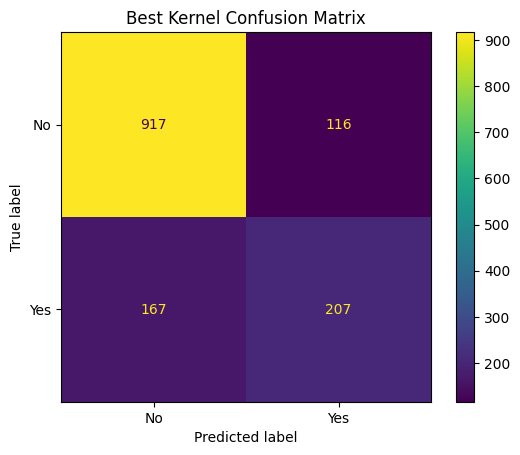

In [11]:
# YOUR CODE HERE — confusion matrix for the best kernel
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

if best_row["Kernel"] == "Linear":
    best_pred = pred_linear

elif best_row["Kernel"] == "RBF":
    best_pred = pred_rbf

else:
    best_pred = pred_poly

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    display_labels=["No", "Yes"]
)

plt.title("Best Kernel Confusion Matrix")
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* The Linear kernel produced the best F1-score of 0.5940. It also achieved the highest accuracy of 0.7989. This is not very surprising because the churn data may be reasonably separable using a simpler linear decision boundary.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* The Polynomial kernel used the most support vectors, with 2760 support vectors. A high support-vector count suggests that more training points are needed to define the decision boundary, which can indicate a more complex model.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* Based on the results, I would prefer the Linear kernel because it achieved the highest F1-score of 0.5940, compared with 0.5509 for RBF and 0.5457 for Polynomial.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [12]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_s)

explained_variance = pca.explained_variance_ratio_.sum()

print("Total Explained Variance Ratio:", explained_variance)

Total Explained Variance Ratio: 0.4511140575062713


In [14]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

C_values = [0.01, 1, 100]

# Mesh grid
x_min = X_train_pca[:, 0].min() - 1
x_max = X_train_pca[:, 0].max() + 1
y_min = X_train_pca[:, 1].min() - 1
y_max = X_train_pca[:, 1].max() + 1


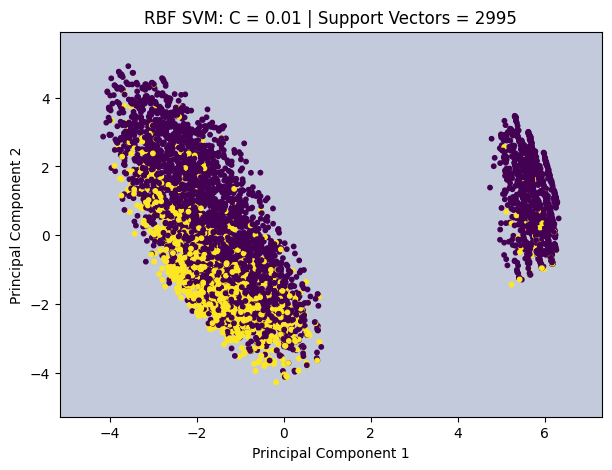

C = 0.01 | Support Vectors = 2995


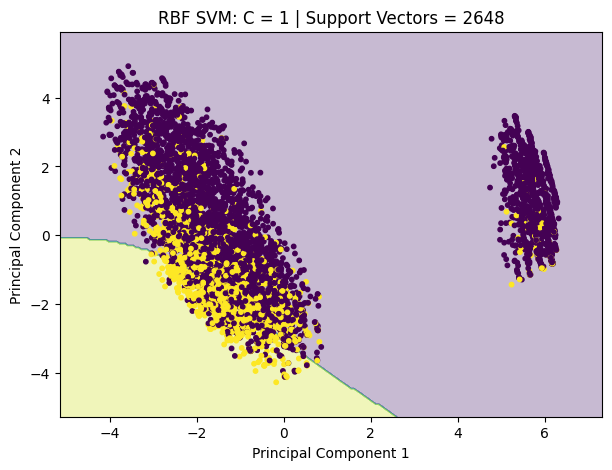

C = 1 | Support Vectors = 2648


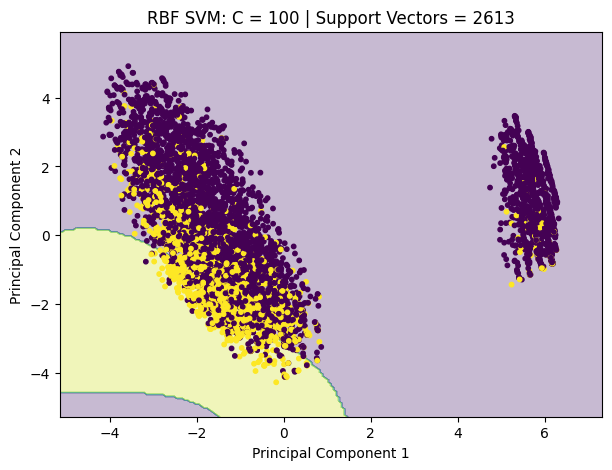

C = 100 | Support Vectors = 2613


In [15]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

for C in C_values:

    model = SVC(
        kernel="rbf",
        C=C,
        random_state=42
    )

    model.fit(X_train_pca, y_train)

    Z = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    )

    Z = Z.reshape(xx.shape)

    support_vectors = model.support_.shape[0]

    plt.figure(figsize=(7, 5))

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.3
    )

    plt.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        s=10
    )

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")

    plt.title(
        f"RBF SVM: C = {C} | Support Vectors = {support_vectors}"
    )

    plt.show()

    print("C =", C, "| Support Vectors =", support_vectors)

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* As C increased from 0.01 to 100, the decision boundary became more flexible and tried harder to classify the training points correctly. A small C produced a smoother and simpler boundary, while a large C produced a more detailed boundary.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:*The number of support vectors decreased as C increased:

C = 0.01 → 2995 support vectors
C = 1 → 2648 support vectors
C = 100 → 2613 support vectors

This matches the expected behavior because a small C allows more margin violations and uses a wider margin, while a large C penalizes violations more strongly.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:*C = 0.01 appears more likely to underfit because it produces a simpler and smoother boundary.

C = 100 appears more likely to overfit because it tries harder to fit the training data and creates a more flexible boundary.

C = 1 gives a more balanced decision boundary.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* The 2-D plot is only an approximate view because PCA reduced the original high-dimensional data to only two dimensions.

The two PCA components explain about 45.11% of the total variance, so more than half of the original information is not shown in this plot. Therefore, the visible decision boundary may not fully represent the real high-dimensional SVM.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    "C": [0.1, 1, 10],
    "gamma": [0.001, 0.01, 0.1]
}

gs = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid,
    cv=5,
    scoring="f1"
)

gs.fit(X_train_s, y_train)

print("Best C:", gs.best_params_["C"])
print("Best Gamma:", gs.best_params_["gamma"])
print("Best CV F1-score:", gs.best_score_)
import pandas as pd

results = pd.DataFrame(gs.cv_results_)

score_grid = results.pivot(
    index="param_C",
    columns="param_gamma",
    values="mean_test_score"
)

score_grid

Best C: 10
Best Gamma: 0.001
Best CV F1-score: 0.5817698428309384


param_gamma,0.001,0.010,0.100
param_C,,,
0.1,0.000000,0.543671,0.459290
1.0,0.571667,0.568563,0.556588
10.0,0.581770,0.575960,0.534619


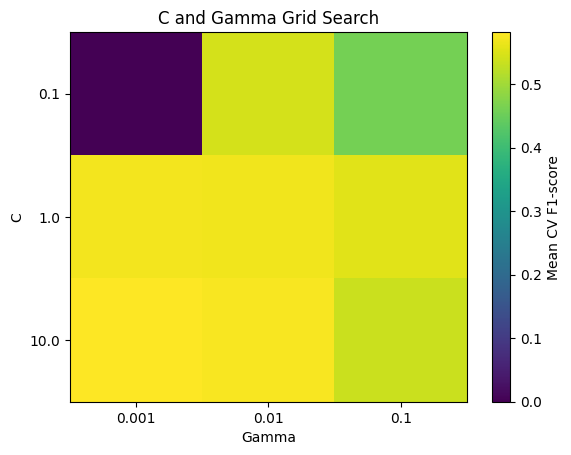

In [21]:
import matplotlib.pyplot as plt

plt.imshow(
    score_grid,
    aspect="auto"
)

plt.colorbar(label="Mean CV F1-score")

plt.xticks(
    range(len(score_grid.columns)),
    score_grid.columns
)

plt.yticks(
    range(len(score_grid.index)),
    score_grid.index
)

plt.xlabel("Gamma")
plt.ylabel("C")
plt.title("C and Gamma Grid Search")

plt.show()

Accuracy: 0.7974413646055437
Precision: 0.6449511400651465
Recall: 0.5294117647058824
F1-score: 0.5814977973568282


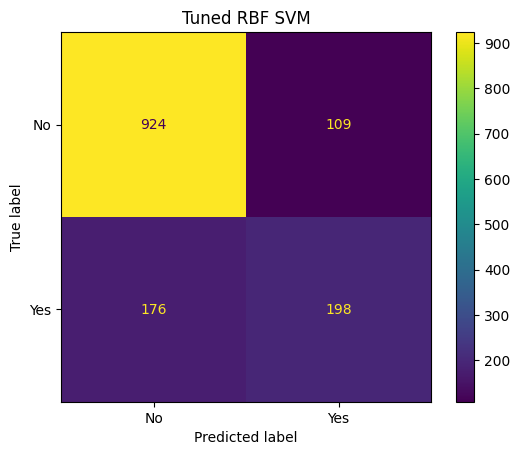

In [23]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

best_svm = gs.best_estimator_

y_pred_tuned = best_svm.predict(X_test_s)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1-score:", f1_score(y_test, y_pred_tuned))
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["No", "Yes"]
)

plt.title("Tuned RBF SVM")
plt.show()

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* The best hyperparameters were C = 10 and gamma = 0.001. The best cross-validated F1-score was 0.5818.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* The best region is around C = 10 with small gamma values. Several combinations produced similar F1-scores, especially for C = 1 and C = 10. This suggests that the model is not extremely sensitive to exact hyperparameter values within this good region, although some combinations perform much worse.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* The cross-validated F1-score was 0.5818 and the final test F1-score was 0.5815. These scores are very close, so the model generalizes well to the test set.

A large gap would suggest that the model may be overfitting or that its performance is not stable across different data splits.
 
(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* The untuned RBF model had an F1-score of 0.5509, while the tuned RBF model improved it to 0.5815.

Accuracy also improved from 0.7868 to 0.7974, recall from 0.4920 to 0.5294, and precision from 0.6259 to 0.6450.

Therefore, hyperparameter tuning was worth the extra computation because it improved the overall performance of the RBF SVM.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


Default Precision: 0.6449511400651465
Default Recall: 0.5294117647058824
Default F1-score: 0.5814977973568282


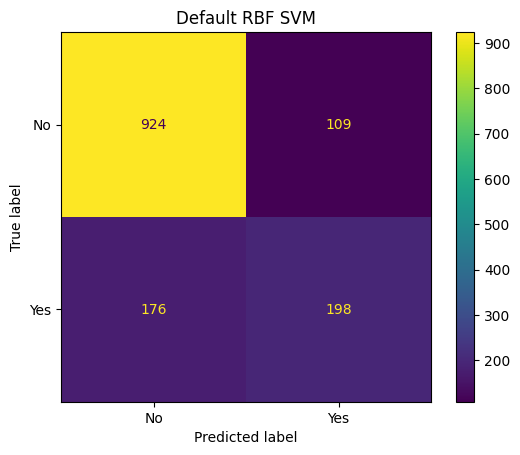

Balanced Precision: 0.4505169867060561
Balanced Recall: 0.8155080213903744
Balanced F1-score: 0.5803996194100857


In [29]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score, f1_score

svm_default = SVC(
    kernel="rbf",
    C=10,
    gamma=0.001,
    probability=True,
    random_state=42
)

svm_default.fit(X_train_s, y_train)

pred_default = svm_default.predict(X_test_s)

print("Default Precision:", precision_score(y_test, pred_default))
print("Default Recall:", recall_score(y_test, pred_default))
print("Default F1-score:", f1_score(y_test, pred_default))


from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_default,
    display_labels=["No", "Yes"]
)

plt.title("Default RBF SVM")
plt.show()


pred_balanced = svm_balanced.predict(X_test_s)

print("Balanced Precision:", precision_score(y_test, pred_balanced))
print("Balanced Recall:", recall_score(y_test, pred_balanced))
print("Balanced F1-score:", f1_score(y_test, pred_balanced))


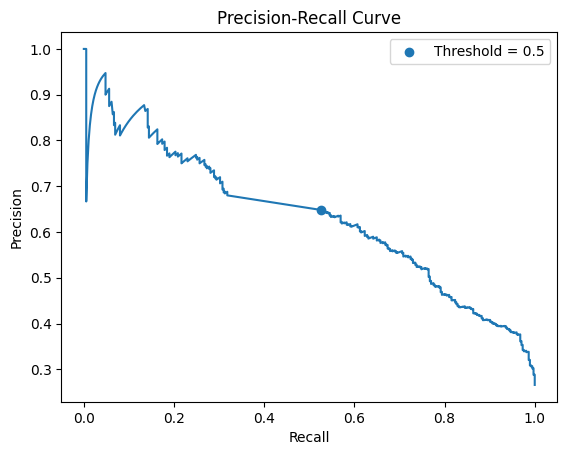

In [28]:
# YOUR CODE HERE — ROC or Precision-Recall curve
from sklearn.svm import SVC

svm_balanced = SVC(
    kernel="rbf",
    C=10,
    gamma=0.001,
    class_weight="balanced",
    probability=True,
    random_state=42
)

svm_balanced.fit(X_train_s, y_train)

from sklearn.metrics import precision_recall_curve, precision_score, recall_score
import matplotlib.pyplot as plt

prob = svm_balanced.predict_proba(X_test_s)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test,
    prob
)

plt.plot(recall, precision)

pred_05 = (prob >= 0.5).astype(int)

p_05 = precision_score(y_test, pred_05)
r_05 = recall_score(y_test, pred_05)

plt.scatter(
    r_05,
    p_05,
    label="Threshold = 0.5"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()

plt.show()

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:*After using class_weight='balanced', precision decreased from 0.6450 to 0.4505, while recall increased from 0.5294 to 0.8155.

So, precision decreased by about 19.44 percentage points, while recall increased by about 28.61 percentage points.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* For a telecom company, missing an actual churner (false negative) is usually more costly because the company loses the chance to retain that customer.

The balanced SVM increased recall from 52.94% to 81.55%, which means it detects many more actual churners. Although precision dropped from 64.50% to 45.05%, the F1-score stayed almost the same (0.5815 vs 0.5804).

Therefore, I would recommend the balanced SVM because detecting more churners is more important for the churn-reduction goal.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* I enabled probability=True in SVC and used predict_proba() to obtain probability-like churn scores for the Precision-Recall curve.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [32]:
# YOUR CODE HERE — cross-model comparison table
# Balanced SVM accuracy
# Balanced SVM metrics
balanced_accuracy = accuracy_score(y_test, pred_balanced)
balanced_precision = precision_score(y_test, pred_balanced)
balanced_recall = recall_score(y_test, pred_balanced)
balanced_f1 = f1_score(y_test, pred_balanced)

comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "KNN",
        "Balanced SVM"
    ],

    "Accuracy": [
        0.785359,
        0.788913,
        0.803838,
        0.776830,
        balanced_accuracy
    ],

    "Precision": [
        0.611111,
        0.628763,
        0.647590,
        0.582873,
        balanced_precision
    ],

    "Recall": [
        0.529412,
        0.502674,
        0.574866,
        0.564171,
        balanced_recall
    ],

    "F1-score": [
        0.567335,
        0.558692,
        0.609065,
        0.573370,
        balanced_f1
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.785359,0.611111,0.529412,0.567335
1,Random Forest,0.788913,0.628763,0.502674,0.558692
2,Logistic Regression,0.803838,0.647590,0.574866,0.609065
3,KNN,0.776830,0.582873,0.564171,0.573370
4,Balanced SVM,0.686567,0.450517,0.815508,0.580400


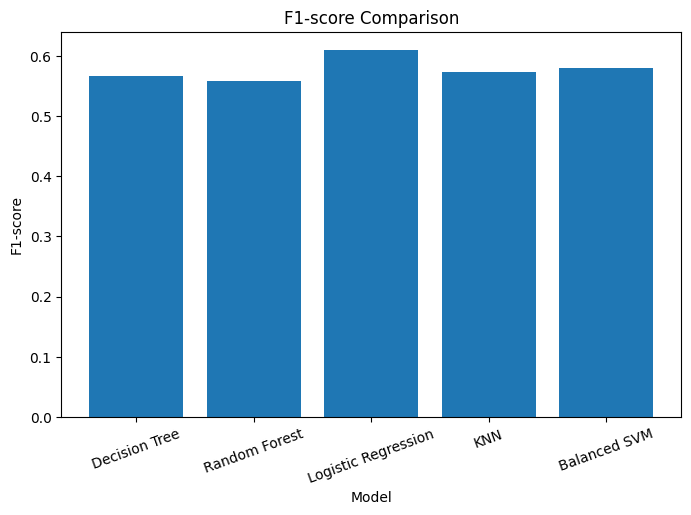

In [34]:
# YOUR CODE HERE — bar chart of F1-score across models
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["F1-score"]
)

plt.xlabel("Model")
plt.ylabel("F1-score")
plt.title("F1-score Comparison")

plt.xticks(rotation=20)

plt.show()

Logistic Regression achieved the highest F1-score, while the Balanced SVM had a slightly lower F1-score but achieved much higher recall.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* Logistic Regression achieved the highest F1-score of 0.6091.

Balanced SVM achieved the highest recall of 0.8155.

Therefore, the model with the highest F1-score and the model with the highest recall are not the same.

Therefore, the model with the best F1-score and the model with the best recall are not the same.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* For overall F1-score, the extra computational cost of SVM was not clearly worth it because Logistic Regression achieved a higher F1-score of 0.6091 compared with 0.5804 for the Balanced SVM.

However, the Balanced SVM achieved a much higher recall of 0.8155, so the extra computation may be useful when detecting as many churners as possible is the main business goal.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* I would recommend the Balanced SVM for deployment because it achieved the highest recall of 0.8155, meaning it detected the largest proportion of actual churners.

Its F1-score was 0.5804. Although its precision was lower at 0.4505, this trade-off is acceptable in a churn-prediction problem because missing an actual churner may be more costly than incorrectly flagging a loyal customer.

Therefore, the Balanced SVM is selected as the final model.

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [37]:
# YOUR CODE HERE — generate and save svm_predictions.csv
# Final chosen model
final_model = svm_balanced

# Predictions
final_pred = final_model.predict(X_test_s)

# Churn probability
final_prob = final_model.predict_proba(X_test_s)[:, 1]

# Create DataFrame
svm_predictions = pd.DataFrame({
    "True_Label": y_test.to_numpy(),
    "Predicted_Label": final_pred,
    "Churn_Probability": final_prob
})

# Save CSV
svm_predictions.to_csv(
    "svm_predictions.csv",
    index=False
)

svm_predictions.head()

,True_Label,Predicted_Label,Churn_Probability
0,0,0,0.078847
1,0,1,0.500000
2,0,0,0.014997
3,1,0,0.098200
4,0,0,0.096732


**Executive Summary**

*Your summary here.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:*The most surprising result was that using class_weight='balanced' increased recall from 0.5294 to 0.8155, although precision decreased from 0.6450 to 0.4505.

(b) If you had one more hour, what would you try next?

*Your answer:* If I had one more hour, I would try SMOTE or feature engineering to improve churn detection while maintaining better precision and F1-score.
